In [2]:
from google.colab import drive  # Import the library needed to mount Google Drive
drive.mount('/content/drive')  # Mount the drive to the '/content/drive' directory

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd  # Import pandas for data manipulation

# Specify the path to the dataset file
file_path = '/content/drive/MyDrive/Lab_14_AI_DataSet/Pumpkin_Seeds_Dataset.xlsx'

# Load the dataset
data = pd.read_excel(file_path)  # Read the Excel file using pandas

# Display the first 5 rows of the dataset
data.head()  # This shows the first 5 rows of the dataset

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness,Class
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207,Çerçevelik
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487,Çerçevelik
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929,Çerçevelik
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624,Çerçevelik
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557,Çerçevelik


In [4]:
from sklearn.preprocessing import StandardScaler  # Import StandardScaler from scikit-learn

# Extract numerical features from the dataset (assuming all columns are numerical except the target)
numerical_data = data.select_dtypes(include=['float64', 'int64'])  # This selects only the numerical columns

# Initialize StandardScaler
scaler = StandardScaler()

# Fit the scaler to the numerical data and transform it (this normalizes the data)
scaled_data = scaler.fit_transform(numerical_data)

# Convert the scaled data back to a pandas DataFrame for easier visualization
scaled_data_df = pd.DataFrame(scaled_data, columns=numerical_data.columns)

# Display the first 5 rows of both the original and scaled dataframes
print("Original Data (First 5 rows):")
print(numerical_data.head())
print("\nScaled Data (First 5 rows):")
print(scaled_data_df.head())

Original Data (First 5 rows):
    Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  Convex_Area  \
0  56276    888.242           326.1485           220.2388        56831   
1  76631   1068.146           417.1932           234.2289        77280   
2  71623   1082.987           435.8328           211.0457        72663   
3  66458    992.051           381.5638           222.5322        67118   
4  66107    998.146           383.8883           220.4545        67117   

   Equiv_Diameter  Eccentricity  Solidity  Extent  Roundness  Aspect_Ration  \
0        267.6805        0.7376    0.9902  0.7453     0.8963         1.4809   
1        312.3614        0.8275    0.9916  0.7151     0.8440         1.7811   
2        301.9822        0.8749    0.9857  0.7400     0.7674         2.0651   
3        290.8899        0.8123    0.9902  0.7396     0.8486         1.7146   
4        290.1207        0.8187    0.9850  0.6752     0.8338         1.7413   

   Compactness  
0       0.8207  
1       0.7487  

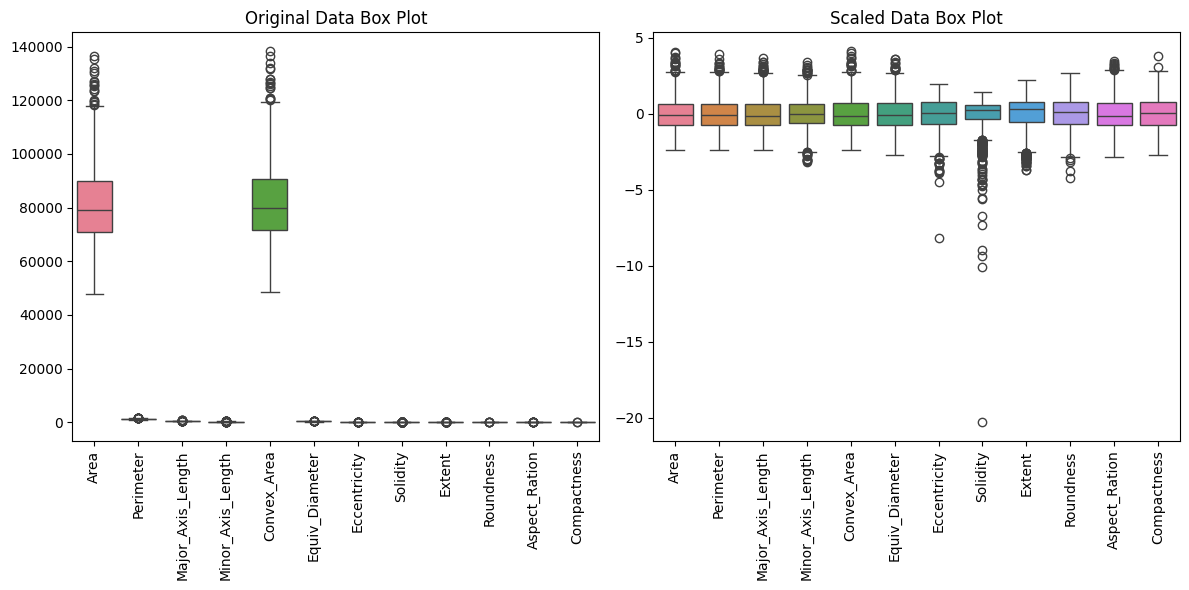

In [5]:
import matplotlib.pyplot as plt  # Import matplotlib for plotting
import seaborn as sns  # Import seaborn for better visualizations

# Set up the plotting environment
plt.figure(figsize=(12, 6))  # Create a figure with a size of 12x6 inches

# Plot box plots for original data
plt.subplot(1, 2, 1)  # Create a subplot (1 row, 2 columns, first plot)
sns.boxplot(data=numerical_data)  # Create a box plot for the original data
plt.title('Original Data Box Plot')  # Title for the first plot
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

# Plot box plots for scaled data
plt.subplot(1, 2, 2)  # Create a subplot (1 row, 2 columns, second plot)
sns.boxplot(data=scaled_data_df)  # Create a box plot for the scaled data
plt.title('Scaled Data Box Plot')  # Title for the second plot
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

# Display the plots
plt.tight_layout()  # Adjust the layout so the plots fit well
plt.show()  # Show the plots

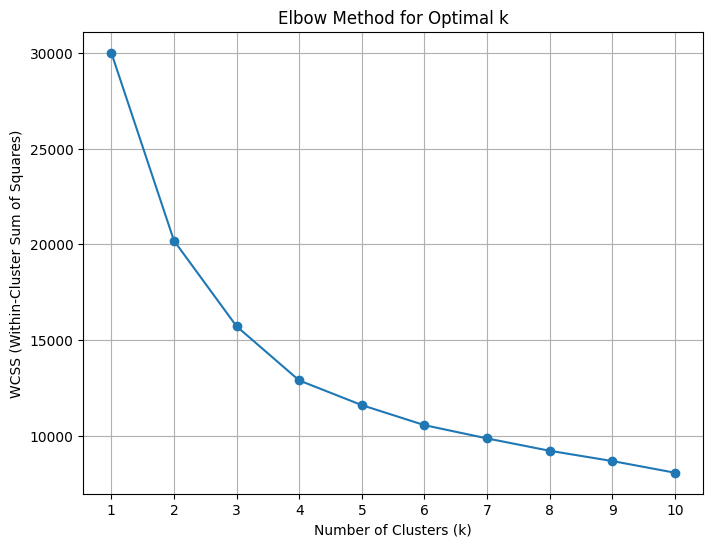

In [6]:
from sklearn.cluster import KMeans  # Import KMeans from scikit-learn
import matplotlib.pyplot as plt  # Import matplotlib for plotting

# Calculate WCSS for different values of k (from 1 to 10)
wcss = []  # List to store WCSS values for each k
for k in range(1, 11):  # Loop over k values from 1 to 10
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)  # Initialize KMeans
    kmeans.fit(scaled_data_df)  # Fit the KMeans model on the scaled data
    wcss.append(kmeans.inertia_)  # Append the WCSS for this k

# Plot the Elbow Curve
plt.figure(figsize=(8, 6))  # Create a figure with a size of 8x6 inches
plt.plot(range(1, 11), wcss, marker='o')  # Plot WCSS for each k
plt.title('Elbow Method for Optimal k')  # Title for the plot
plt.xlabel('Number of Clusters (k)')  # x-axis label
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')  # y-axis label
plt.xticks(range(1, 11))  # Set x-axis ticks from 1 to 10
plt.grid(True)  # Add a grid for better readability
plt.show()  # Show the plot

In [10]:
from sklearn.preprocessing import LabelEncoder  # Import LabelEncoder

# Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Convert the true class labels (strings) to integers
encoded_true_labels = label_encoder.fit_transform(true_labels)

# Evaluate the clustering performance using the encoded true labels
accuracy = accuracy_score(encoded_true_labels, cluster_labels)  # Accuracy (not ideal for clustering but will give a sense)
conf_matrix = confusion_matrix(encoded_true_labels, cluster_labels)  # Confusion Matrix
ari = adjusted_rand_score(encoded_true_labels, cluster_labels)  # Adjusted Rand Index

# Print the results
print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)
print(f"Adjusted Rand Index (ARI): {ari}")

Accuracy: 0.5932
Confusion Matrix:
[[1007  202   91]
 [ 144  476  580]
 [   0    0    0]]
Adjusted Rand Index (ARI): 0.33723099899104153


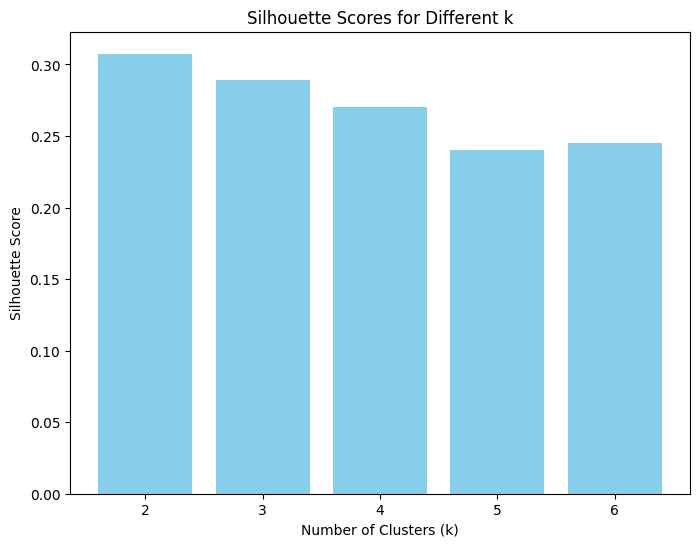

In [11]:
from sklearn.metrics import silhouette_score  # Import silhouette_score

# List to store silhouette scores for each k
silhouette_scores = []

# Loop over k values from 2 to 6
for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(scaled_data_df)  # Fit and predict the clusters
    score = silhouette_score(scaled_data_df, cluster_labels)  # Compute silhouette score
    silhouette_scores.append(score)  # Append the score to the list

# Plot the Silhouette Scores
plt.figure(figsize=(8, 6))
plt.bar(range(2, 7), silhouette_scores, color='skyblue')
plt.title('Silhouette Scores for Different k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 7))  # Set x-axis ticks from 2 to 6
plt.show()

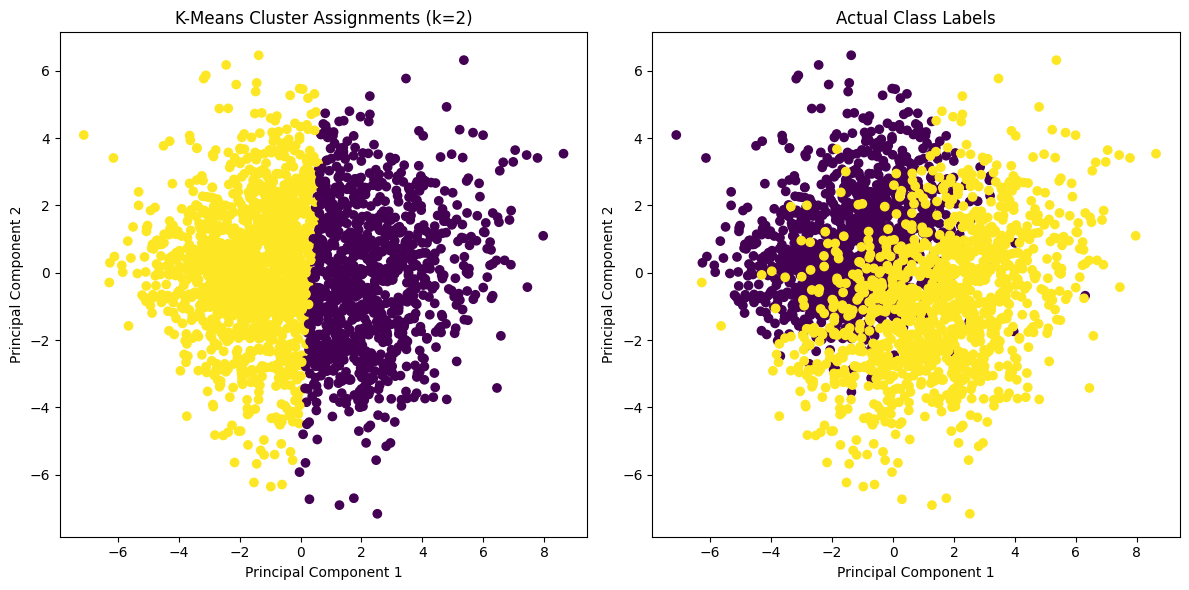

In [12]:
from sklearn.decomposition import PCA  # Import PCA for dimensionality reduction
import matplotlib.pyplot as plt  # Import matplotlib for plotting

# Apply PCA to reduce the data to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_df)  # Transform the scaled data into 2D

# Train K-Means with k=2 on the PCA-reduced data
kmeans_pca = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
cluster_labels_pca = kmeans_pca.fit_predict(pca_data)  # Fit the model and predict clusters

# Create a scatter plot with two subplots side by side
plt.figure(figsize=(12, 6))

# Subplot 1: Show K-Means Cluster Assignments
plt.subplot(1, 2, 1)
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=cluster_labels_pca, cmap='viridis')  # Plot clusters
plt.title('K-Means Cluster Assignments (k=2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Subplot 2: Show Actual Class Labels
plt.subplot(1, 2, 2)
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=data['Class'].apply(lambda x: label_encoder.transform([x])[0]), cmap='viridis')  # Plot true classes
plt.title('Actual Class Labels')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Display the plots
plt.tight_layout()
plt.show()

### Conclusion

Based on the analysis performed using K-Means clustering and various evaluation methods, it can be concluded that K-Means was able to cluster the pumpkin seeds dataset with moderate success. The Elbow Method suggested an optimal value of `k = 3`, although the Silhouette Score analysis suggested a different optimal value. Despite this, the K-Means model with `k = 3` still yielded a reasonable clustering result, as evidenced by the clustering performance metrics.

- **Evaluation Metrics**:
  - The **Accuracy** of 0.5932 indicates that the model is not perfectly aligned with the true class labels, but there is some clustering structure.
  - The **Confusion Matrix** showed that one of the clusters did not contain any samples from the true classes, which suggests that K-Means struggled to fully capture the structure of the data.
  - The **Adjusted Rand Index (ARI)** of 0.3372 also indicates a moderate correlation between the predicted clusters and the true labels, suggesting room for improvement.

- **Limitation of K-Means**:
  One significant limitation of K-Means clustering is its sensitivity to the initial cluster centroids and its tendency to struggle with data that has varying cluster sizes and densities. In this case, we observed that one of the clusters was empty, which could be a result of K-Means being unable to capture the full complexity of the data. Additionally, K-Means assumes spherical clusters, which may not be suitable for datasets with non-spherical or overlapping clusters.

Overall, while K-Means provided useful clustering insights, further experimentation with other clustering algorithms (e.g., DBSCAN or Gaussian Mixture Models) could lead to better results.